# 6 · Prove: hypothesis tests, does the score work, and is it fair?

**Syllabus:** Module 3 (estimation, hypothesis testing), Module 4 (model evaluation),
Module 6 (bias and fairness, transparency, accountability).

Three questions:

1. Which beliefs about the Play Store survive a formal test?
2. Does the viability score separate apps that succeeded from apps that did not, on
   apps it never saw, including apps launched *after* the 2018 data was collected?
3. Does it work equally well for every kind of app?

**Fixed before computing:** every test is two-sided at α = 0.05, and the seven
p-values are corrected together by **Holm's method** (testing many hypotheses at once
makes some "significant" by luck; Holm raises the bar for each in turn). Rank-based
tests are used because ratings and installs are skewed and bounded.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
import common as C
import engine as E

C.style()
rng = np.random.default_rng(C.SEED)
apps = C.load_apps()
reviews = C.load_reviews()
now = C.load_2026()

## 6.1 Seven hypotheses

| | Null hypothesis H0 | Alternative H1 | Test |
|---|---|---|---|
| H1 | Paid and free apps have the same rating distribution | They differ | Mann-Whitney U |
| H2 | Ratings have the same distribution in every category | At least one differs | Kruskal-Wallis |
| H3 | Reaching 1M installs is independent of content rating | It depends on it | χ² independence |
| H4 | Apps updated in the last 6 months of the snapshot have the same installs as older ones | They differ | Mann-Whitney U |
| H5 | Successful and unsuccessful apps get equally positive reviews | They differ | Mann-Whitney U on mean polarity |
| H6 | App size and installs are unrelated | They are related | Spearman ρ |
| H7 | Category mean ratings were the same in 2018 and 2026 | They changed | Wilcoxon signed-rank (paired by category) |

In [2]:
tests = {}
r = apps.dropna(subset=["rating"])
u = stats.mannwhitneyu(r.loc[r["paid"] == 1, "rating"], r.loc[r["paid"] == 0, "rating"])
tests["H1 paid vs free rating"] = (u.pvalue, f"median {r.loc[r['paid'] == 1, 'rating'].median():.2f} vs {r.loc[r['paid'] == 0, 'rating'].median():.2f}")
kw = stats.kruskal(*[gr["rating"].to_numpy() for _, gr in r.groupby("category")])
eps2 = (kw.statistic - r["category"].nunique() + 1) / (len(r) - r["category"].nunique())
tests["H2 rating across categories"] = (kw.pvalue, f"H = {kw.statistic:.0f}, ε² = {eps2:.3f}")
main4 = apps[apps["content"].isin(["Everyone", "Teen", "Mature 17+", "Everyone 10+"])]
tab = pd.crosstab(main4["content"], main4["success"])
chi = stats.chi2_contingency(tab)
v = np.sqrt(chi.statistic / (tab.to_numpy().sum() * (min(tab.shape) - 1)))
tests["H3 success vs content rating"] = (chi.pvalue, f"Cramér's V = {v:.3f}")
recent = apps["updated"] >= apps["updated"].max() - pd.DateOffset(months=6)
u = stats.mannwhitneyu(apps.loc[recent, "log_installs"], apps.loc[~recent, "log_installs"])
tests["H4 recent update vs installs"] = (u.pvalue, f"median installs {10 ** apps.loc[recent, 'log_installs'].median():,.0f} vs {10 ** apps.loc[~recent, 'log_installs'].median():,.0f}")
pol = reviews.groupby("app").agg(polarity=("polarity", "mean"), n=("polarity", "size")).query("n >= 10").join(apps.set_index("app")["success"], how="inner")
u = stats.mannwhitneyu(pol.loc[pol["success"] == 1, "polarity"], pol.loc[pol["success"] == 0, "polarity"])
tests["H5 review polarity vs success"] = (u.pvalue, f"mean {pol.loc[pol['success'] == 1, 'polarity'].mean():.3f} vs {pol.loc[pol['success'] == 0, 'polarity'].mean():.3f} ({len(pol)} apps)")
s = apps.dropna(subset=["size_mb"])
rho = stats.spearmanr(s["size_mb"], s["log_installs"])
tests["H6 size vs installs"] = (rho.pvalue, f"ρ = {rho.statistic:.3f}")
pair = apps.groupby("category")["rating"].mean().to_frame("y2018").join(now.groupby("category")["rating"].agg(["mean", "size"]), how="inner")
pair = pair[pair["size"] >= 20]
w = stats.wilcoxon(pair["mean"], pair["y2018"])
tests["H7 rating 2018 vs 2026"] = (w.pvalue, f"{(pair['mean'] > pair['y2018']).sum()} of {len(pair)} categories higher in 2026")

names = list(tests)
p = np.array([tests[n][0] for n in names])
order = np.argsort(p)
holm = np.empty_like(p)
running = 0.0
for rank, i in enumerate(order):
    running = max(running, min(1.0, (len(p) - rank) * p[i]))
    holm[i] = running
table = pd.DataFrame({"p": p, "p_holm": holm, "reject_H0": holm < 0.05, "effect": [tests[n][1] for n in names]}, index=names)
pd.set_option("display.max_colwidth", 80)
print(table)
C.record("prove.tests", table.assign(p=table["p"].map(float), p_holm=table["p_holm"].map(float)).to_dict(orient="index"))

                                           p         p_holm  reject_H0  \
H1 paid vs free rating          8.108375e-11   2.432513e-10       True   
H2 rating across categories     2.543710e-33   1.271855e-32       True   
H3 success vs content rating    2.871191e-31   1.148476e-30       True   
H4 recent update vs installs   2.283238e-131  1.369943e-130       True   
H5 review polarity vs success   4.728432e-07   9.456863e-07       True   
H6 size vs installs            2.157314e-187  1.510120e-186       True   
H7 rating 2018 vs 2026          1.886003e-04   1.886003e-04       True   

                                                           effect  
H1 paid vs free rating                        median 4.40 vs 4.30  
H2 rating across categories                   H = 238, ε² = 0.025  
H3 success vs content rating                   Cramér's V = 0.123  
H4 recent update vs installs    median installs 500,000 vs 10,000  
H5 review polarity vs success      mean 0.184 vs 0.246 (726 apps)  

A small p-value with a large sample can still be a tiny effect, so each test reports an
effect size beside it. With almost 10,000 apps, even small differences are
"significant"; the effect column says whether they matter.

## 6.2 Bootstrap confidence intervals

The **bootstrap** estimates how much a number would move if the data were collected
again: resample the apps with replacement 2,000 times, recompute, and take the middle
95% of the results.

In [3]:
def boot(fn, *groups, n=2000):
    vals = [fn(*[g[rng.integers(0, len(g), len(g))] for g in groups]) for _ in range(n)]
    return np.percentile(vals, [2.5, 97.5])


paid_r, free_r = r.loc[r["paid"] == 1, "rating"].to_numpy(), r.loc[r["paid"] == 0, "rating"].to_numpy()
# Ratings sit on a 0.1 grid, so a difference of medians barely moves under resampling: the mean is used.
ci_rating = boot(lambda a, b: a.mean() - b.mean(), paid_r, free_r)
rec, old = apps.loc[recent, "success"].to_numpy(), apps.loc[~recent, "success"].to_numpy()
ci_success = boot(lambda a, b: a.mean() - b.mean(), rec, old)
boots = {"paid_minus_free_mean_rating": {"estimate": float(paid_r.mean() - free_r.mean()), "ci95": ci_rating.round(3).tolist()},
         "recent_minus_old_success_rate": {"estimate": float(rec.mean() - old.mean()), "ci95": ci_success.round(3).tolist()}}
print(boots); C.record("prove.bootstrap", boots)

{'paid_minus_free_mean_rating': {'estimate': 0.09590291163595754, 'ci95': [0.048, 0.14]}, 'recent_minus_old_success_rate': {'estimate': 0.2476801346439103, 'ci95': [0.229, 0.266]}}


## 6.3 Does the viability score work?

The score is meant for ideas, which have no outcome yet. To test it, existing apps are
treated as ideas: each app's **name** is typed in as the idea, its category, content
rating and price are given, and the score is compared with what actually happened.

* **Held-out 2018 apps:** the engine is fitted on train + validation apps, and scores
  the test apps.
* **Out of time:** the engine is fitted on all of 2018, and scores the 2026 apps that
  were *released after the snapshot was taken*: new entrants it could not have seen.

**Two designs are compared.** The first design of this project scored an idea by hand:
35% neighbours' installs (demand), 20% low crowding (competition), 15% low neighbour
rating (room to do better) and 30% the learned success probability, each as a
percentile. The intuition is the usual business one: a market with demand, few
competitors and unhappy users is an opportunity. The second design, which the engine
now uses, lets the data decide. The score is the percentile of the success model's
probability, which has already learned how much each of those signals matters, and in
which direction. **AUC** again: the chance that a successful app scores higher than an
unsuccessful one.

                                          2018 held-out apps  \
neighbours' installs (demand)                          0.778   
low crowding (competition)                             0.425   
low neighbour rating (room to do better)               0.443   
learned score (engine)                                 0.833   
hand-weighted opportunity score                        0.798   

                                          2026 apps released after the snapshot  
neighbours' installs (demand)                                             0.652  
low crowding (competition)                                                0.415  
low neighbour rating (room to do better)                                  0.474  
learned score (engine)                                                    0.710  
hand-weighted opportunity score                                           0.674  
learned weights (standardised): {'nb_demand': 1.099, 'nb_crowding': -0.03, 'nb_rating': 0.056}


{'2018 held-out apps': {'success': [0.041, 0.208, 0.452, 0.737], 'apps': [466, 475, 471, 520], 'rises_every_band': True}, '2026 apps released after the snapshot': {'success': [0.157, 0.376, 0.522, 0.706], 'apps': [108, 194, 255, 279], 'rises_every_band': True}}


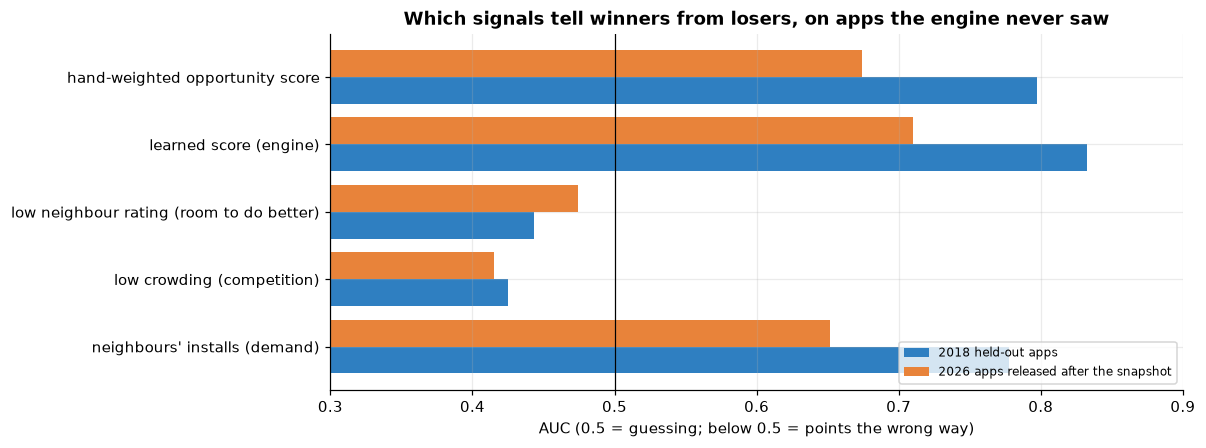

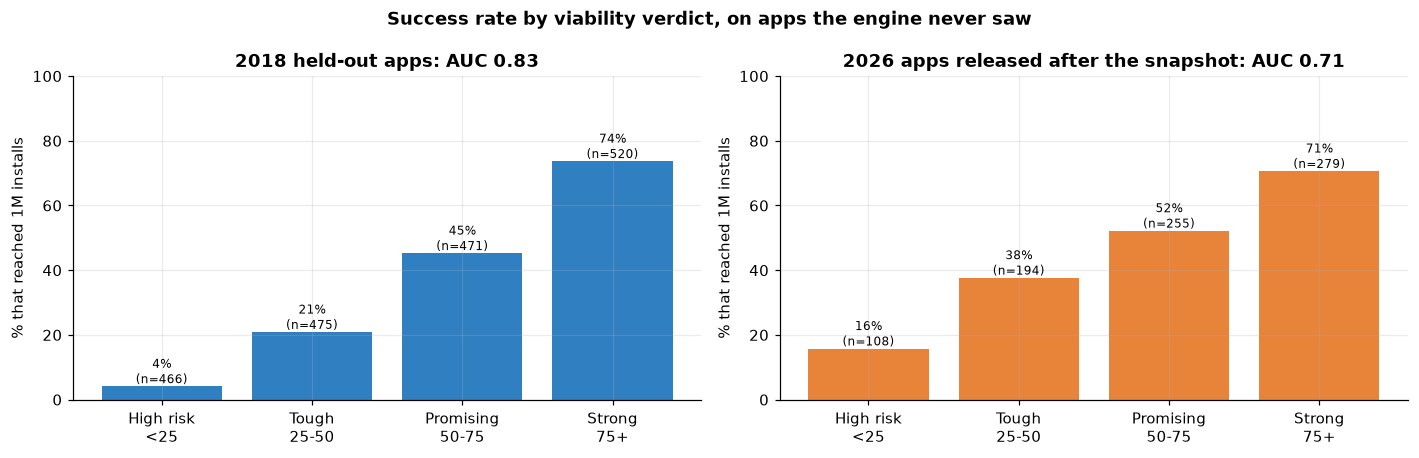

In [4]:
apps["split"] = C.split(apps)
fit_part, test = apps[apps["split"] != "test"].drop(columns="split"), apps[apps["split"] == "test"].drop(columns="split")
eng = E.fit(fit_part)
eng_all = E.fit(apps.drop(columns="split"))
now["released_on"] = pd.to_datetime(now["released"], format="%b %d, %Y", errors="coerce")
new = now[(now["released_on"] > apps["updated"].max()) & now["category"].isin(apps["category"].unique())].copy()
new["content"] = new["contentRating"]
new["price"] = new["price"].fillna(0)
OLD_WEIGHTS = {"demand": 0.35, "competition": 0.20, "gap": 0.15, "success": 0.30}


def judged(e, d):
    row = e.rows(d)
    p = e.success_model.predict_proba(row)[:, 1]
    ref = e.reference
    parts = {"demand": E.pct(row["nb_demand"], ref["nb_demand"]), "competition": 1 - E.pct(row["nb_crowding"], ref["nb_crowding"]),
             "gap": 1 - E.pct(row["nb_rating"], ref["nb_rating"]), "success": E.pct(p, ref["p_success"])}
    out = pd.DataFrame(parts, index=d.index)
    out["hand-weighted opportunity score"] = sum(w * out[k] for k, w in OLD_WEIGHTS.items())
    return out.rename(columns={"demand": "neighbours' installs (demand)", "competition": "low crowding (competition)",
                               "gap": "low neighbour rating (room to do better)", "success": "learned score (engine)"}), p


sets = {"2018 held-out apps": (eng, test), "2026 apps released after the snapshot": (eng_all, new)}
comparison, valid = {}, {}
for label, (e, d) in sets.items():
    parts, p = judged(e, d)
    d["p_success"], d["score"] = p, parts["learned score (engine)"].to_numpy() * 100
    comparison[label] = {col: roc_auc_score(d["success"], parts[col]) for col in parts}
    valid[label] = {"apps": len(d), "success_rate": float(d["success"].mean()), "auc_score": comparison[label]["learned score (engine)"],
                    "spearman_score_installs": float(stats.spearmanr(d["score"], d["log_installs"]).statistic)}
comp = pd.DataFrame(comparison)
print(comp.round(3))
C.record("prove.score_comparison", comp.round(4).to_dict(orient="index"))
C.record("prove.score_validation", pd.DataFrame(valid).T.round(4).to_dict(orient="index"))
w = pd.Series(eng.success_model[-1].coef_[0], eng.success_model[0].get_feature_names_out())
C.record("prove.learned_weights", {k: float(w[f"num__{k}"]) for k in ["nb_demand", "nb_crowding", "nb_rating"]})
print("learned weights (standardised):", {k: round(float(w[f"num__{k}"]), 3) for k in ["nb_demand", "nb_crowding", "nb_rating"]})

fig, ax = plt.subplots(figsize=(10, 4.2))
yy = np.arange(len(comp))
ax.barh(yy - 0.2, comp.iloc[:, 0], 0.4, color=C.PALETTE["main"], label=comp.columns[0])
ax.barh(yy + 0.2, comp.iloc[:, 1], 0.4, color=C.PALETTE["accent"], label=comp.columns[1])
ax.set_yticks(yy, comp.index); ax.axvline(0.5, color="k", lw=0.8); ax.set_xlim(0.3, 0.9)
ax.set_xlabel("AUC (0.5 = guessing; below 0.5 = points the wrong way)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Which signals tell winners from losers, on apps the engine never saw")
C.save(fig, "prove_score_comparison")

BANDS, LABELS = [0, 25, 50, 75, 100], ["High risk\n<25", "Tough\n25-50", "Promising\n50-75", "Strong\n75+"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
band_rates = {}
for ax, (label, (_, d)), col in zip(axes, sets.items(), [C.PALETTE["main"], C.PALETTE["accent"]]):
    rate = d.groupby(pd.cut(d["score"], BANDS, labels=LABELS, include_lowest=True), observed=False)["success"].agg(["mean", "size"])
    band_rates[label] = {"success": rate["mean"].round(3).tolist(), "apps": rate["size"].tolist(),
                         "rises_every_band": bool(rate["mean"].is_monotonic_increasing)}
    ax.bar(range(4), rate["mean"] * 100, color=col)
    for i, (m, n) in enumerate(rate.to_numpy()):
        ax.text(i, m * 100 + 1, f"{m:.0%}\n(n={int(n)})", ha="center", fontsize=8)
    ax.set_xticks(range(4), rate.index); ax.set_ylabel("% that reached 1M installs"); ax.set_ylim(0, 100)
    ax.set_title(f"{label}: AUC {valid[label]['auc_score']:.2f}")
fig.suptitle("Success rate by viability verdict, on apps the engine never saw", fontweight="bold")
fig.tight_layout(); C.save(fig, "prove_score_validation")
print(band_rates); C.record("prove.verdict_bands", band_rates)

**Reading it.** The learned score separates winners from losers on apps it never saw,
and still does on apps launched years after its data was collected. Each verdict band
succeeds more often than the one below it, on both test sets.

The hand-weighted design loses on both. The reason is in the middle rows: low crowding
and low neighbour ratings point the **wrong way** (AUC below 0.5). Niches that are
crowded and well rated are where apps succeed, because crowding follows demand:
developers pile into markets that pay. The intuition "few competitors, unhappy users"
describes a gap, but in this data a gap more often means a market nobody wants.
Survivorship could explain the 2018 result alone (only surviving incumbents are
seen). The 2026 check argues against that: those apps are new entrants into the 2018
neighbourhoods, and crowding still did not hurt them. The success model learned this
by itself: its weight for crowding is close to zero, while neighbours' installs
dominate. That is why the engine now scores with the learned model and shows
competition and ratings only as context.

The out-of-time check is harder in one way (a different store, eight years on) and
easier in another (the 2026 apps were found through search, which favours apps that
did well). So the 2026 number confirms that the signal transfers, but should not be
read as the score's exact accuracy.

## 6.4 Fairness: does it work equally for every kind of app?

A score that works for games but not for medical apps would steer founders unfairly.
Fairness is checked two ways on the held-out 2018 apps, per category and for free
against paid:

* **Discrimination:** AUC within the group (can it still tell winners from losers?).
* **Calibration:** mean predicted probability of success against the actual rate. A
  gap means the engine is systematically too hopeful or too gloomy about that group.

                     apps  actual  predicted    auc  calibration_gap
group                                                               
FOOD_AND_DRINK         22   0.591      0.436  0.496           -0.155
AUTO_AND_VEHICLES      17   0.294      0.163  0.583           -0.131
DATING                 34   0.176      0.244  0.643            0.067
VIDEO_PLAYERS          33   0.394      0.487  0.665            0.093
GAME                  189   0.677      0.571  0.727           -0.106
SPORTS                 65   0.400      0.361  0.744           -0.039
FINANCE                69   0.304      0.293  0.748           -0.012
SOCIAL                 48   0.333      0.428  0.748            0.095
BUSINESS               84   0.107      0.151  0.750            0.044
TOOLS                 166   0.392      0.335  0.774           -0.057
SHOPPING               40   0.500      0.542  0.775            0.042
COMMUNICATION          63   0.524      0.431  0.781           -0.093
PERSONALIZATION        75   0.280 

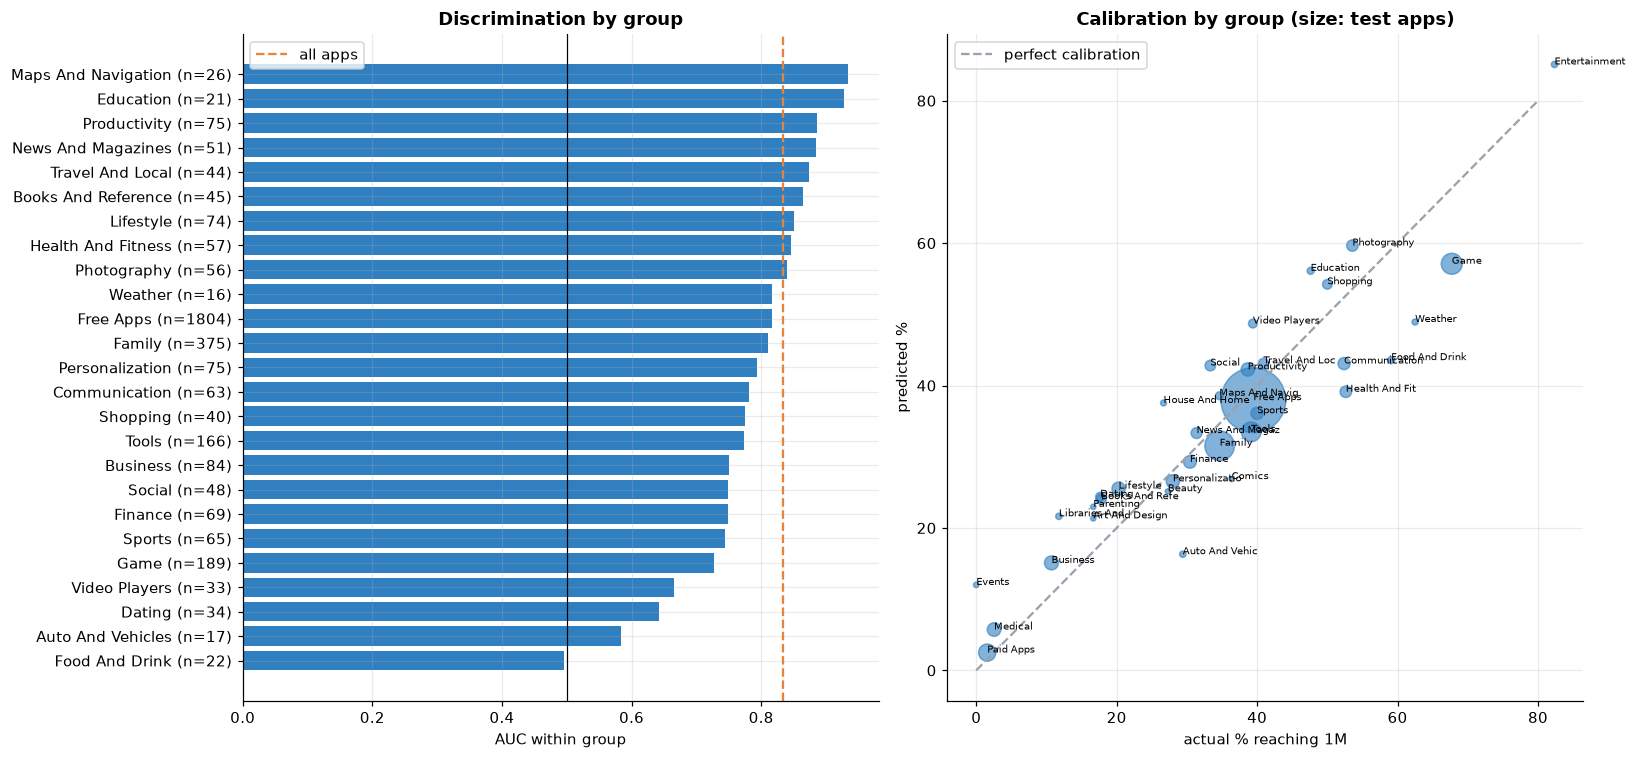

In [5]:
fair = []
for grp_name, grp in list(test.groupby("category")) + [("Free apps", test[test["paid"] == 0]), ("Paid apps", test[test["paid"] == 1])]:
    pos = grp["success"].sum()
    fair.append({"group": grp_name, "apps": len(grp), "actual": grp["success"].mean(), "predicted": grp["p_success"].mean(),
                 "auc": roc_auc_score(grp["success"], grp["p_success"]) if 5 <= pos <= len(grp) - 5 else np.nan})
fair = pd.DataFrame(fair).set_index("group")
fair["calibration_gap"] = fair["predicted"] - fair["actual"]
print(fair.round(3).sort_values("auc"))
C.record("prove.fairness", fair.round(4).to_dict(orient="index"))
summary = {"groups_with_auc": int(fair["auc"].notna().sum()), "auc_min": float(fair["auc"].min()), "auc_max": float(fair["auc"].max()),
           "auc_min_group": fair["auc"].idxmin(), "auc_max_group": fair["auc"].idxmax(),
           "max_abs_calibration_gap": float(fair["calibration_gap"].abs().max()),
           "max_gap_group": fair["calibration_gap"].abs().idxmax()}
print(summary); C.record("prove.fairness_summary", summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
f = fair.dropna(subset=["auc"]).sort_values("auc")
axes[0].barh([f"{i.replace('_', ' ').title()} (n={int(n)})" for i, n in zip(f.index, f["apps"])], f["auc"], color=C.PALETTE["main"])
axes[0].axvline(roc_auc_score(test["success"], test["p_success"]), color=C.PALETTE["accent"], ls="--", label="all apps")
axes[0].axvline(0.5, color="k", lw=0.8); axes[0].set_xlabel("AUC within group"); axes[0].legend(); axes[0].set_title("Discrimination by group")
axes[1].scatter(fair["actual"] * 100, fair["predicted"] * 100, s=fair["apps"], color=C.PALETTE["main"], alpha=0.6)
for gname, rw in fair.iterrows():
    axes[1].annotate(gname.replace("_", " ").title()[:14], (rw["actual"] * 100, rw["predicted"] * 100), fontsize=6.5)
axes[1].plot([0, 80], [0, 80], ls="--", color=C.PALETTE["muted"], label="perfect calibration")
axes[1].set_xlabel("actual % reaching 1M"); axes[1].set_ylabel("predicted %"); axes[1].legend(); axes[1].set_title("Calibration by group (size: test apps)")
fig.tight_layout(); C.save(fig, "prove_fairness")

## 6.5 Ethics: what the user is and is not told

* **Transparency.** The app never shows a bare number: every score comes with the exact
  contribution of each input (they add up to the model's answer) and the real apps
  that drove it.
* **Uncertainty.** Chapter 3 showed that most of what decides installs is invisible
  before launch. The app says so, and calls its output a verdict band, not a forecast.
* **Bias in the data.** The 2018 data is a snapshot (survivors only: removed apps are
  absent); reviews cover mostly popular apps; the 2026 scrape is a search sample. Each
  is stated where it is used.
* **Privacy.** Only public store listings and anonymous review text are used; no user
  names or identifiers are stored or shown.
* **Accountability.** Every number in the app and the report is written by these
  notebooks into one results file, and can be traced back to the code that made it.